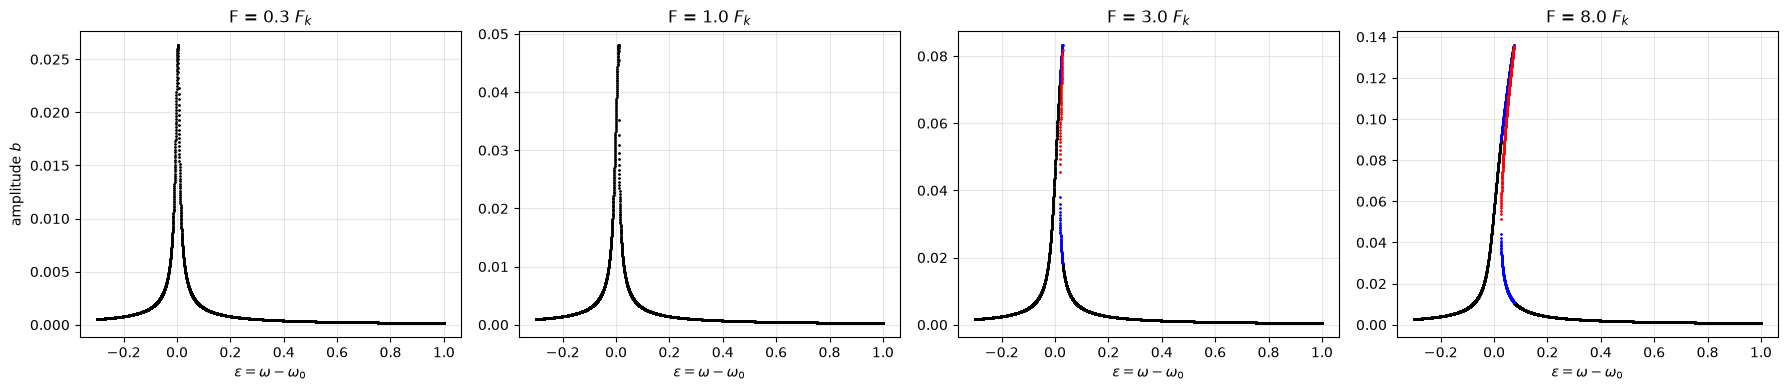

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

kappa = 4.0
lam = 0.006

F_k = 8 * lam**3 / (3 * np.sqrt(3) * kappa)

def solve_branches(F, eps_arr):
    """Return eps, b, color-code for every real positive root of the cubic in B=b^2."""
    out = []
    for eps in eps_arr:
        coeffs = [kappa**2, -2 * eps * kappa, eps**2 + lam**2, -F]
        roots = np.roots(coeffs)
        real = roots[np.abs(roots.imag) < 1e-9 * max(1, np.abs(roots).max())].real
        real = real[real > 0]
        for B in real:
            u = eps - kappa * B
            G_B = u**2 - 2 * kappa * B * u + lam**2   # dG/dB: >0 stable, <0 unstable
            out.append((eps, np.sqrt(B), len(real), G_B))
    return np.array(out)

multipliers = [0.3, 1.0, 3.0, 8.0]
eps_arr = np.linspace(-0.3, 1.0, 6000)

fig, axes = plt.subplots(1, 4, figsize=(18, 4))

for ax, mult in zip(axes, multipliers):
    F = mult * F_k
    d = solve_branches(F, eps_arr)
    e, b, n, GB = d.T

    one = n == 1
    ax.plot(e[one], b[one], 'k.', ms=2)

    three = n == 3
    stable = three & (GB > 0)
    unstable = three & (GB < 0)
    ax.plot(e[stable], b[stable], 'b.', ms=2)
    ax.plot(e[unstable], b[unstable], 'r.', ms=2)

    ax.set_title(rf'F = {mult} $F_k$')
    ax.set_xlabel(r'$\epsilon = \omega - \omega_0$')
    ax.grid(alpha=0.3)

axes[0].set_ylabel('amplitude $b$')
plt.tight_layout()
plt.show()

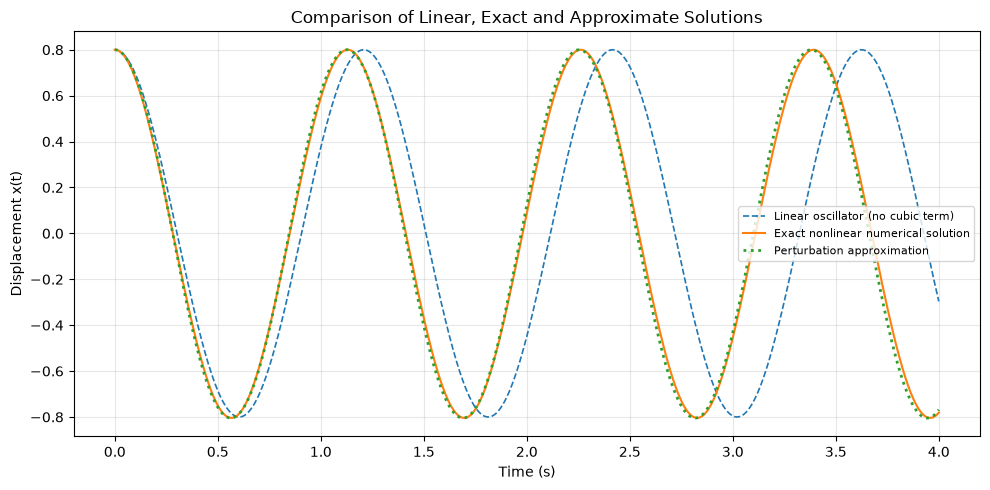

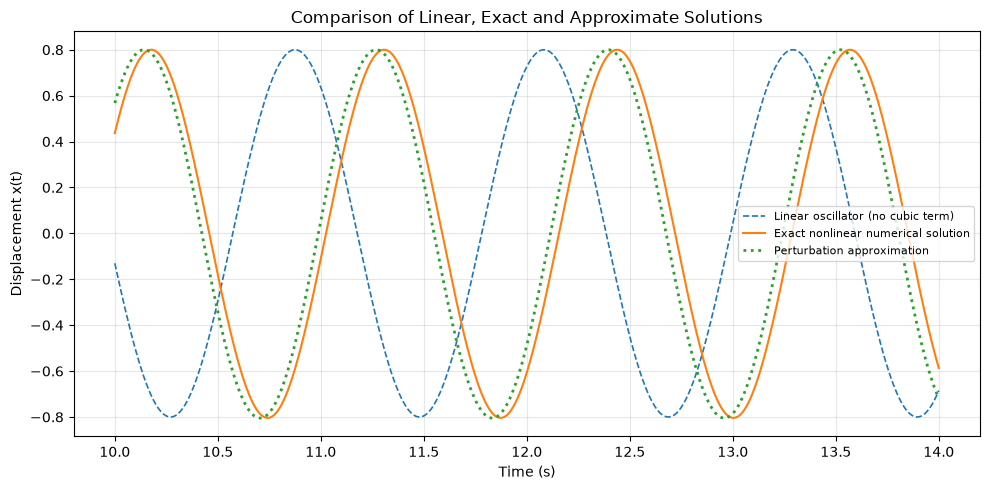

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
from scipy.optimize import brentq


w0 = 5.2
alpha = 0.3
beta = 8.0
x0 = 0.8          # initial displacement, v0 = 0

# ---------- exact numerical solution ----------
def rhs(t, y):
    x, v = y
    return [v, -w0**2 * x - alpha * x**2 - beta * x**3]

t_eval = np.linspace(0, 14, 20000)
sol = solve_ivp(rhs, (0, 14), [x0, 0.0], t_eval=t_eval,
                rtol=1e-11, atol=1e-12)
x_exact = sol.y[0]

# ---------- linear oscillator ----------
x_lin = x0 * np.cos(w0 * t_eval)

# ---------- perturbation approximation ----------
def x_pert(t, a):
    w = w0 + (3*beta/(8*w0) - 5*alpha**2/(12*w0**3)) * a**2
    x1 = a * np.cos(w * t)
    x2 = -alpha*a**2/(2*w0**2) + alpha*a**2/(6*w0**2) * np.cos(2*w*t)
    x3 = a**3/(16*w0**2) * (alpha**2/(3*w0**2) - beta/2) * np.cos(3*w*t)
    return x1 + x2 + x3

# choose a so that x(0) = x0 (the notes' a is the first-harmonic amplitude,
# so a = x0 is only approximately right). Set a = x0 instead if you prefer.
a = brentq(lambda a: x_pert(0.0, a) - x0, 0.5 * x0, 1.5 * x0)
x_p = x_pert(t_eval, a)

# ---------- plotting ----------
def make_plot(tmin, tmax):
    m = (t_eval >= tmin) & (t_eval <= tmax)
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(t_eval[m], x_lin[m], '--', color='tab:blue',
            lw=1.2, label='Linear oscillator (no cubic term)')
    ax.plot(t_eval[m], x_exact[m], '-', color='tab:orange',
            lw=1.5, label='Exact nonlinear numerical solution')
    ax.plot(t_eval[m], x_p[m], ':', color='tab:green',
            lw=2, label='Perturbation approximation')
    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Displacement x(t)')
    ax.set_title('Comparison of Linear, Exact and Approximate Solutions')
    ax.grid(alpha=0.3)
    ax.legend(loc='center right', fontsize=8)
    plt.tight_layout()

make_plot(0, 4)      # Figure 1
make_plot(10, 14)    # Figure 2
plt.show()